In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload Wine.csv to the notebook working folder, or update this path.
df = pd.read_csv("../data\Wine.csv")

print("Shape:", df.shape)
display(df.head())
print("\nDataset information:")
df.info()
print("\nMissing values:")
print(df.isnull().sum())

Shape: (178, 14)


<>:7: SyntaxWarning: invalid escape sequence '\W'
<>:7: SyntaxWarning: invalid escape sequence '\W'
C:\Users\neelp\AppData\Local\Temp\ipykernel_9096\3787636328.py:7: SyntaxWarning: invalid escape sequence '\W'
  df = pd.read_csv("../data\Wine.csv")


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
 13  Customer_Segment      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB

Miss

In [4]:
target_col = "Customer_Segment"

if target_col in df.columns:
    X = df.drop(columns=[target_col])
else:
    print("Target column not found; using all columns as features.")
    X = df.copy()

X = pd.get_dummies(X, drop_first=True)
X = X.select_dtypes(include=np.number)
X = X.fillna(X.median())

print("Feature shape:", X.shape)
display(X.head())

Feature shape: (178, 13)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)
print(X_scaled[:5])

Scaled data shape: (178, 13)
[[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]
 [ 1.69154964 -0.34681064  0.4879264  -0.80925118  0.93091845  2.49144552
   1.46652465 -0.98187536  1.03215473  1.18606801 -0.42754369  1.18407144
   2.33457383]
 [ 0.29570023  0.22769377  1.84040254  0.45194578  1.28198515  0.80899739
   0.66335127  0.22679555  0.40140444 -0.31927553  0.36217728  0.44960118
  -0.03787401]]


## GMM model

In [6]:
gmm = GaussianMixture(
    n_components=3,
    covariance_type="full",
    random_state=42
)

gmm.fit(X_scaled)

labels = gmm.predict(X_scaled)

print("Cluster labels:")
print(labels)

Cluster labels:
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


In [7]:
probabilities = gmm.predict_proba(X_scaled)

print("First 5 rows of cluster probabilities:")
print(probabilities[:5])

First 5 rows of cluster probabilities:
[[1.36788523e-13 4.07977194e-51 1.00000000e+00]
 [1.80955191e-09 2.12970309e-45 9.99999998e-01]
 [1.77819585e-09 4.31184715e-56 9.99999998e-01]
 [1.83249181e-22 2.35180356e-87 1.00000000e+00]
 [3.94006740e-04 1.24671913e-23 9.99605993e-01]]


In [9]:
score = silhouette_score(X_scaled, labels)
print("Silhouette Score:", score)

print("BIC:", gmm.bic(X_scaled))
print("AIC:", gmm.aic(X_scaled))

Silhouette Score: 0.2848589191898987
BIC: 5842.330291718671
AIC: 4843.250256926956


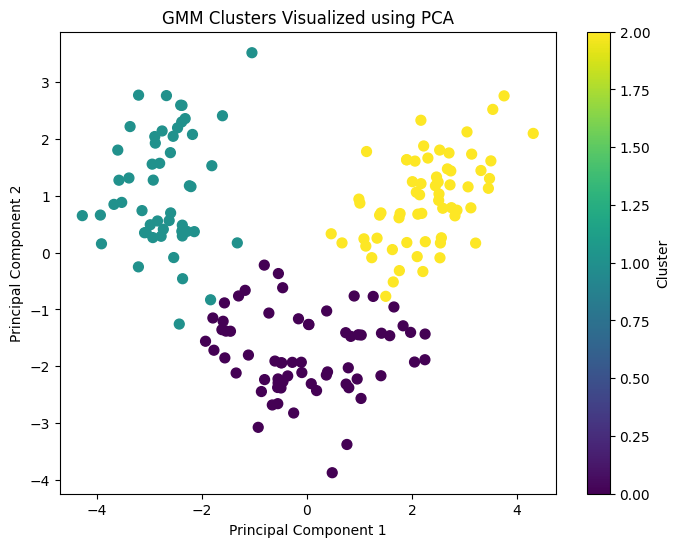

In [10]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels, cmap="viridis", s=50
)
plt.title("GMM Clusters Visualized using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.show()

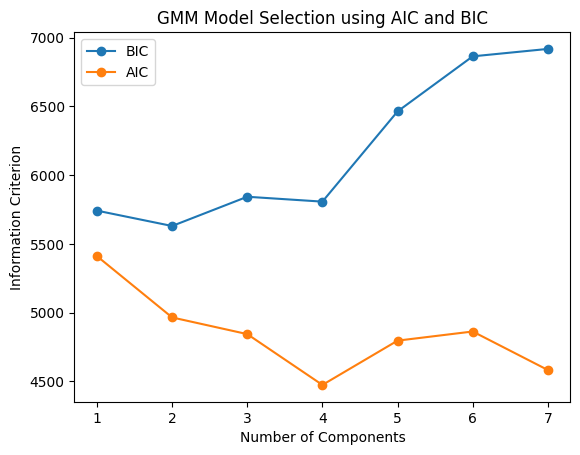

Best number of components by BIC: 2


In [12]:
n_components = range(1, 8)
bic_values = []
aic_values = []

for k in n_components:
    model = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42
    )
    model.fit(X_scaled)
    bic_values.append(model.bic(X_scaled))
    aic_values.append(model.aic(X_scaled))

plt.plot(list(n_components), bic_values, marker="o", label="BIC")
plt.plot(list(n_components), aic_values, marker="o", label="AIC")
plt.xlabel("Number of Components")
plt.ylabel("Information Criterion")
plt.title("GMM Model Selection using AIC and BIC")
plt.legend()
plt.show()

print("Best number of components by BIC:", list(n_components)[int(np.argmin(bic_values))])

## Analysis / Conclusion

- GMM assumes that the data is generated from a mixture of Gaussian distributions.
- `n_components` specifies the number of Gaussian components.
- `predict()` assigns each observation to its most likely component.
- `predict_proba()` returns the probability of belonging to each component.
- Lower AIC/BIC values are preferred when comparing candidate GMM models fitted to the same data.